# Group 20 – Feature Selection using Reinforcement Learning (WPBC)
(Part A: TD(0) replication, Part B: Q-learning extension and comparison)
**Replication of:** Rasoul, Adewole, Akakpo (2021), *Feature Selection using Reinforcement Learning* (arXiv:2101.09460)

**Part A (this notebook):** TD(0) replication on WPBC with Group-20 seeds.  
**Part B (next step):** Q-learning extension + comparison with TD(0) (the agent is written so a Q-learning class can be dropped in).

### Paper details that are ambiguous (decisions made here, document them in your report)
| Issue in paper | Decision in this notebook |
|---|---|
| Eq. 5 defines AOR as V(Ft) − V(Ft+1) (sign reversed vs. Eq. 1) | Use Eq. 1: reward = acc(next) − acc(current) |
| Eq. 6 updates AOR with V(F), text says average of *rewards* | Incremental mean of the **reward** |
| Eq. 7 / text mention a UCB-like term that is never defined | Plain ε-greedy over AOR |
| "State value" max ≈ 3.5 (Fig. 1) exceeds any accuracy | Not reproducible from Eq. 1+4 alone; we log max V anyway |
| ε is not given, "choose with high probability" | ε = probability of **random** action (matches Fig. 2: larger ε → more states visited) |
| α, γ, #episodes, SVM C/γ, CV folds not given | Set in CONFIG, tunable |
| Accuracy reported on the same data used to search (optimistic) | We report **both** paper-style (search CV score) and honest held-out test score |


In [ ]:
!pip -q install ucimlrepo skrebate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.4/55.4 kB 2.5 MB/s eta 0:00:00


In [ ]:
import numpy as np, pandas as pd, time, warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score
from sklearn.feature_selection import mutual_info_classif, chi2, f_classif
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")

CONFIG = dict(
    SEEDS=[20, 40, 60, 80, 100],   # <-- replace with YOUR Group-20 seeds (must differ from Group 2)
    TEST_SIZE=0.20,
    CV_FOLDS=5,                    # CV used inside the reward (training data only)
    N_EPISODES=300,
    ALPHA=0.1,                     # TD learning rate
    GAMMA=0.9,                     # discount
    EPSILON=0.3,                   # prob. of random action in the epsilon-greedy phase
    REWARD_METRIC="accuracy",      # paper-faithful. Try "balanced_accuracy" (class imbalance 47R/151N)
)
CONFIG

{'SEEDS': [20, 40, 60, 80, 100],
 'TEST_SIZE': 0.2,
 'CV_FOLDS': 5,
 'N_EPISODES': 300,
 'ALPHA': 0.1,
 'GAMMA': 0.9,
 'EPSILON': 0.3,
 'REWARD_METRIC': 'accuracy'}

In [ ]:
# ---------- Load WPBC (UCI id=16) ----------
try:
    from ucimlrepo import fetch_ucirepo
    w = fetch_ucirepo(id=16)
    Xdf = w.data.features.copy()
    ydf = w.data.targets.iloc[:, 0].copy()
except Exception as e:
    print("ucimlrepo failed, falling back to direct URL:", e)
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wpbc.data"
    base = ["radius","texture","perimeter","area","smoothness","compactness","concavity","concave_points","symmetry","fractal_dim"]
    cols = ["ID","Outcome","Time"] + [f"{b}_{s}" for s in ["mean","se","worst"] for b in base] + ["tumor_size","lymph_node_status"]
    raw = pd.read_csv(url, header=None, names=cols, na_values="?")
    ydf = raw["Outcome"]; Xdf = raw.drop(columns=["Outcome"])

# Drop identifier and leaking column (Time = recurrence/disease-free time)
drop = [c for c in Xdf.columns if c.lower() in ("id", "time")]
Xdf = Xdf.drop(columns=drop).apply(pd.to_numeric, errors="coerce")
y = (ydf.astype(str).str.upper().str.strip() == "R").astype(int).values   # 1 = recurrence
X = Xdf.values.astype(float)
FEATURES = list(Xdf.columns)
N_FEAT = X.shape[1]
print("dropped:", drop, "| X:", X.shape, "| R:", y.sum(), "N:", (y==0).sum(), "| NaNs:", int(np.isnan(X).sum()))

dropped: ['Time'] | X: (198, 32) | R: 47 N: 151 | NaNs: 4


In [ ]:
# ---------- Subset evaluator (reward source) ----------
def make_model():
    # imputation + scaling live INSIDE the pipeline -> fitted per CV fold (no leakage)
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         SVC(kernel="rbf", C=1.0, gamma="scale"))

class SubsetEvaluator:
    """Scores a feature subset (bitmask) by stratified-CV score of a Gaussian SVM. Cached."""
    def __init__(self, X, y, cv_folds, metric, seed):
        self.X, self.y, self.metric = X, y, metric
        self.cv = StratifiedKFold(cv_folds, shuffle=True, random_state=seed)
        self.cache, self.n_evals = {}, 0
    def score(self, mask):
        if mask in self.cache: return self.cache[mask]
        idx = [i for i in range(self.X.shape[1]) if (mask >> i) & 1]
        s = cross_val_score(make_model(), self.X[:, idx], self.y, cv=self.cv, scoring=self.metric).mean()
        self.cache[mask] = s; self.n_evals += 1
        return s

def mask_to_idx(mask, n): return [i for i in range(n) if (mask >> i) & 1]

def holdout_metrics(Xtr, ytr, Xte, yte, idx):
    m = make_model().fit(Xtr[:, idx], ytr); p = m.predict(Xte[:, idx])
    return dict(acc=accuracy_score(yte, p), bal_acc=balanced_accuracy_score(yte, p),
                recall_R=recall_score(yte, p, pos_label=1, zero_division=0))

In [ ]:
# ---------- TD(0) feature-selection agent (paper's method) ----------
class TD0FeatureSelector:
    def __init__(self, ev, n, alpha, gamma, epsilon, seed):
        self.ev, self.n, self.alpha, self.gamma, self.eps = ev, n, alpha, gamma, epsilon
        self.rng = np.random.default_rng(seed)
        self.full = (1 << n) - 1
        self.V = {}                       # state value table (bitmask -> V)
        self.count = np.zeros(n)          # times each feature was selected (row 1 of the 2xn array)
        self.aor = np.zeros(n)            # Average Of Reward per feature   (row 2)
        self.hist = dict(maxV=[], n_states=[], best_score=[])

    def _pick(self, mask):
        avail = [f for f in range(self.n) if not (mask >> f) & 1]
        seen = mask in self.V
        if seen and self.rng.random() > self.eps:                 # epsilon-greedy (exploit) phase
            a = np.array([self.aor[f] for f in avail])
            return avail[self.rng.choice(np.flatnonzero(a == a.max()))]
        return avail[self.rng.integers(len(avail))]               # random phase (unseen state / explore)

    def run_episode(self):
        size = self.rng.integers(1, self.n)                       # random start state
        start = self.rng.choice(self.n, size, replace=False)
        mask = int(sum(1 << int(f) for f in start))
        while mask != self.full:
            f = self._pick(mask); nmask = mask | (1 << f)
            r = self.ev.score(nmask) - self.ev.score(mask)        # Eq. 1
            self.count[f] += 1; k = self.count[f]
            self.aor[f] = ((k - 1) * self.aor[f] + r) / k         # Eq. 6 (incremental mean of rewards)
            v, vn = self.V.get(mask, 0.0), self.V.get(nmask, 0.0) if nmask != self.full else 0.0
            self.V[mask] = v + self.alpha * (r + self.gamma * vn - v)   # Eq. 4  TD(0)
            mask = nmask

    def run(self, n_episodes):
        for _ in range(n_episodes):
            self.run_episode()
            self.hist["maxV"].append(max(self.V.values()))
            self.hist["n_states"].append(len(self.V))
            self.hist["best_score"].append(max(self.ev.cache.values()))

    def best_subset(self):
        """Highest search-CV score among visited subsets (ties -> smaller subset)."""
        m = max(self.ev.cache, key=lambda k: (self.ev.cache[k], -bin(k).count("1")))
        return m, self.ev.cache[m]

    def best_by_value(self):
        """Paper-literal: state with max V (note: V of weak states can be large since gain remains)."""
        m = max(self.V, key=self.V.get); return m, self.ev.cache.get(m, np.nan)

    def ranking(self):
        return list(np.argsort(-self.aor, kind="stable"))

In [ ]:
# ---------- Run TD(0) replication over seeds ----------
cfg = CONFIG; rows, agents, splits = [], {}, {}
for seed in cfg["SEEDS"]:
    t0 = time.time()
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=cfg["TEST_SIZE"], stratify=y, random_state=seed)
    splits[seed] = (Xtr, Xte, ytr, yte)
    ev = SubsetEvaluator(Xtr, ytr, cfg["CV_FOLDS"], cfg["REWARD_METRIC"], seed)
    ag = TD0FeatureSelector(ev, N_FEAT, cfg["ALPHA"], cfg["GAMMA"], cfg["EPSILON"], seed)
    ag.run(cfg["N_EPISODES"]); agents[seed] = ag
    bm, bscore = ag.best_subset(); idx = mask_to_idx(bm, N_FEAT)
    vm, vscore = ag.best_by_value()
    rl = holdout_metrics(Xtr, ytr, Xte, yte, idx)
    allf = holdout_metrics(Xtr, ytr, Xte, yte, list(range(N_FEAT)))
    rows.append(dict(seed=seed, n_selected=len(idx), search_cv_score=bscore,
                     test_acc=rl["acc"], test_bal_acc=rl["bal_acc"], test_recall_R=rl["recall_R"],
                     allfeat_test_acc=allf["acc"], allfeat_test_bal_acc=allf["bal_acc"],
                     maxV_state_size=bin(vm).count("1"), maxV_state_cv=vscore,
                     states_visited=len(ag.V), svm_evals=ev.n_evals, secs=time.time()-t0))
    print(f"seed {seed}: |S*|={len(idx)} searchCV={bscore:.3f} test_acc={rl['acc']:.3f} "
          f"(all feats {allf['acc']:.3f}) states={len(ag.V)} {time.time()-t0:.0f}s")
res_td0 = pd.DataFrame(rows).set_index("seed")
res_td0

seed 20: |S*|=6 searchCV=0.791 test_acc=0.775 (all feats 0.800) states=4277 201s
seed 40: |S*|=7 searchCV=0.785 test_acc=0.800 (all feats 0.775) states=4181 168s
seed 60: |S*|=7 searchCV=0.791 test_acc=0.775 (all feats 0.775) states=4792 190s
seed 80: |S*|=4 searchCV=0.798 test_acc=0.800 (all feats 0.775) states=4547 185s
seed 100: |S*|=11 searchCV=0.779 test_acc=0.800 (all feats 0.775) states=4547 180s


,n_selected,search_cv_score,test_acc,test_bal_acc,test_recall_R,allfeat_test_acc,allfeat_test_bal_acc,maxV_state_size,maxV_state_cv,states_visited,svm_evals,secs
seed,,,,,,,,,,,,
20,6,0.791129,0.775,0.539427,0.111111,0.800,0.555556,3,0.747177,4277,4278,200.897015
40,7,0.784879,0.800,0.555556,0.111111,0.775,0.500000,31,0.728226,4181,4182,167.924656
60,7,0.791331,0.775,0.539427,0.111111,0.775,0.539427,6,0.740927,4792,4793,189.527790
80,4,0.797581,0.800,0.555556,0.111111,0.775,0.500000,2,0.740524,4547,4548,184.988166
100,11,0.778831,0.800,0.555556,0.111111,0.775,0.500000,4,0.734476,4547,4548,179.787911


In [ ]:
# ---------- Summary: paper-style vs honest ----------
s = res_td0.agg(["mean", "std"]).T
print("Paper reports 76.29 +/- 0.007 (%) on WPBC (search-score style, not held-out).\n")
print(f"Paper-style (CV score of best subset on training data): {100*res_td0.search_cv_score.mean():.2f} +/- {100*res_td0.search_cv_score.std():.2f}")
print(f"Held-out test accuracy (RL subset):                      {100*res_td0.test_acc.mean():.2f} +/- {100*res_td0.test_acc.std():.2f}")
print(f"Held-out test accuracy (all features):                   {100*res_td0.allfeat_test_acc.mean():.2f} +/- {100*res_td0.allfeat_test_acc.std():.2f}")
print(f"Held-out balanced accuracy (RL / all):                   {100*res_td0.test_bal_acc.mean():.2f} / {100*res_td0.allfeat_test_bal_acc.mean():.2f}")
print(f"Majority-class baseline accuracy:                        {100*max(y.mean(),1-y.mean()):.2f}")
s

Paper reports 76.29 +/- 0.007 (%) on WPBC (search-score style, not held-out).

Paper-style (CV score of best subset on training data): 78.88 +/- 0.71
Held-out test accuracy (RL subset):                      79.00 +/- 1.37
Held-out test accuracy (all features):                   78.00 +/- 1.12
Held-out balanced accuracy (RL / all):                   54.91 / 51.90
Majority-class baseline accuracy:                        76.26


,mean,std
n_selected,7.000000,2.549510e+00
search_cv_score,0.788750,7.135787e-03
test_acc,0.790000,1.369306e-02
test_bal_acc,0.549104,8.834235e-03
test_recall_R,0.111111,1.551584e-17
allfeat_test_acc,0.780000,1.118034e-02
allfeat_test_bal_acc,0.518996,2.662964e-02
maxV_state_size,9.200000,1.227599e+01
maxV_state_cv,0.738266,7.189698e-03
states_visited,4468.800000,2.430560e+02


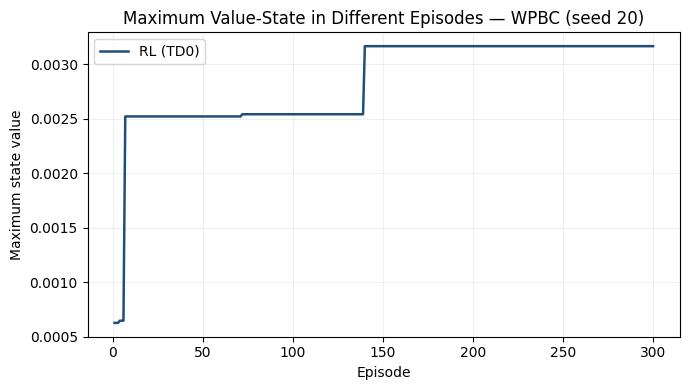

In [ ]:
# ---------- Paper Figure 1 analogue: maximum state value per episode ----------

# Define the color locally to avoid NameError
TD0_COLOR = "#1F4E79"

seed0 = cfg["SEEDS"][0]
h = agents[seed0].hist

plt.figure(figsize=(7, 4))
plt.plot(
    np.arange(1, len(h["maxV"]) + 1),
    h["maxV"],
    color=TD0_COLOR,
    lw=1.8,
    label="RL (TD0)"
)

plt.xlabel("Episode")
plt.ylabel("Maximum state value")
plt.title(f"Maximum Value-State in Different Episodes — WPBC (seed {seed0})")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()


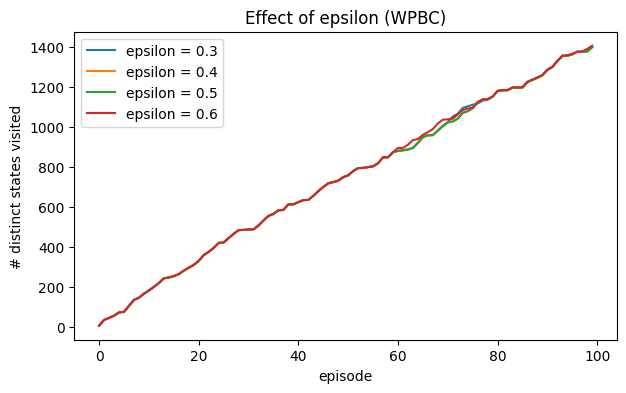

In [ ]:
# ---------- Fig 2 analogue: effect of epsilon on #states visited ----------
plt.figure(figsize=(7, 4))
for eps in [0.3, 0.4, 0.5, 0.6]:
    Xtr, Xte, ytr, yte = splits[seed0]
    ev = SubsetEvaluator(Xtr, ytr, cfg["CV_FOLDS"], cfg["REWARD_METRIC"], seed0)
    ag = TD0FeatureSelector(ev, N_FEAT, cfg["ALPHA"], cfg["GAMMA"], eps, seed0); ag.run(100)
    plt.plot(ag.hist["n_states"], label=f"epsilon = {eps}")
plt.xlabel("episode"); plt.ylabel("# distinct states visited"); plt.title("Effect of epsilon (WPBC)"); plt.legend(); plt.show()

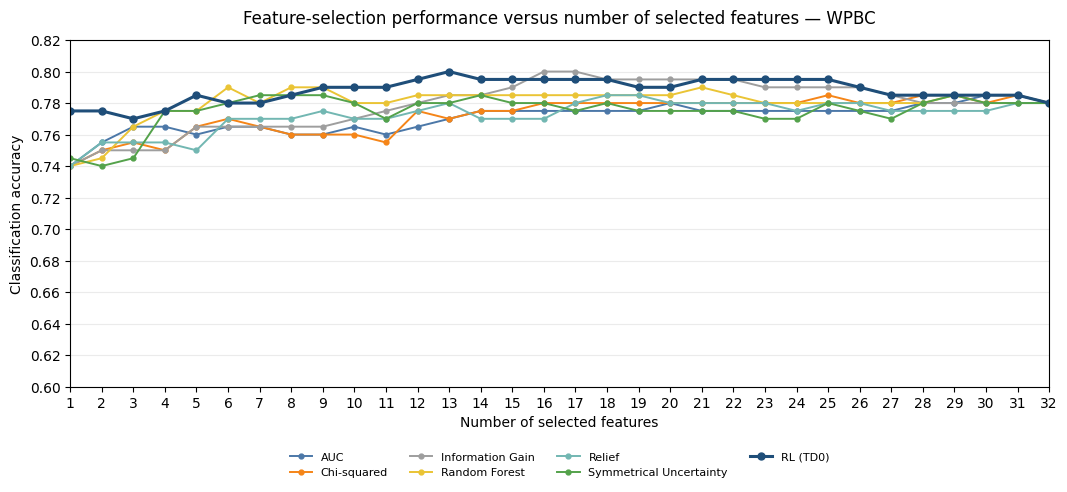

,best_k,best_mean_accuracy,mean_accuracy_over_all_k
RL (TD0),13.0,0.800,0.787969
Random Forest,6.0,0.790,0.780156
Information Gain,16.0,0.800,0.778750
Symmetrical Uncertainty,29.0,0.785,0.774844
Relief,18.0,0.785,0.772188
Chi-squared,28.0,0.785,0.772031
AUC,30.0,0.785,0.770625


Minimum observed accuracy: 0.600
Maximum observed accuracy: 0.825
Some results fall outside the displayed Y-axis range. The graph clips them visually; their actual values are unchanged.


In [ ]:
# ---------- WPBC Feature Selection: Research Paper Comparison ----------
# Methods: AUC, Chi-squared, Information Gain, Random Forest,
#          Relief, Symmetrical Uncertainty, RL (TD0)
# Q-learning can be added later using the same plotting configuration.

from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PAPER_COLORS = {
    "AUC": "#4C78A8",
    "Chi-squared": "#F58518",
    "Information Gain": "#9E9E9E",
    "Random Forest": "#EAC435",
    "Relief": "#72B7B2",
    "Symmetrical Uncertainty": "#54A24B",
    "RL (TD0)": "#1F4E79",
    "RL (Q-learning)": "#B279A2",
}

# ---------- Symmetrical Uncertainty ----------

def symmetrical_uncertainty(x, y, bins=8):
    x = pd.Series(x).copy()
    x = x.fillna(x.median())

    if x.nunique() <= 1:
        return 0.0

    xd = pd.qcut(
        x,
        q=min(bins, x.nunique()),
        labels=False,
        duplicates="drop"
    )

    xd = pd.Series(xd).reset_index(drop=True)
    yd = pd.Series(y).reset_index(drop=True).astype(int)

    mi = mutual_info_classif(
        xd.to_numpy().reshape(-1, 1),
        yd,
        discrete_features=True,
        random_state=0
    )[0]

    px = xd.value_counts(normalize=True).to_numpy()
    py = yd.value_counts(normalize=True).to_numpy()

    Hx = -np.sum(px * np.log(px + 1e-12))
    Hy = -np.sum(py * np.log(py + 1e-12))

    return float(2 * mi / (Hx + Hy + 1e-12))


# ---------- Filter-method feature rankings ----------

def filter_rankings(Xtr, ytr, seed):
    imputer = SimpleImputer(strategy="median")
    Xi = imputer.fit_transform(Xtr)

    Xs = StandardScaler().fit_transform(Xi)
    Xm = MinMaxScaler().fit_transform(Xi)

    rankings = {}

    # 1. AUC
    auc_scores = []

    for j in range(Xi.shape[1]):
        try:
            score = roc_auc_score(ytr, Xi[:, j])
            auc_scores.append(max(score, 1 - score))
        except Exception:
            auc_scores.append(0.5)

    rankings["AUC"] = np.argsort(-np.asarray(auc_scores))

    # 2. Chi-squared
    chi_scores, _ = chi2(Xm, ytr)
    chi_scores = np.nan_to_num(
        chi_scores,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )
    rankings["Chi-squared"] = np.argsort(-chi_scores)

    # 3. Information Gain
    ig_scores = mutual_info_classif(
        Xi,
        ytr,
        random_state=seed
    )
    rankings["Information Gain"] = np.argsort(-ig_scores)

    # 4. Random Forest
    rf = RandomForestClassifier(
        n_estimators=300,
        random_state=seed
    )
    rf.fit(Xi, ytr)

    rankings["Random Forest"] = np.argsort(
        -rf.feature_importances_
    )

    # 5. Relief
    try:
        from skrebate import ReliefF

        relief = ReliefF(
            n_features_to_select=min(5, Xi.shape[1]),
            n_neighbors=min(10, max(1, len(ytr) - 1))
        )
        relief.fit(Xs, np.asarray(ytr))

        rankings["Relief"] = np.argsort(
            -relief.feature_importances_
        )

    except Exception as e:
        print(f"Relief skipped for seed {seed}: {e}")

    # 6. Symmetrical Uncertainty

    su_scores = np.array([
        symmetrical_uncertainty(Xi[:, j], ytr)
        for j in range(Xi.shape[1])
    ])

    rankings["Symmetrical Uncertainty"] = np.argsort(-su_scores)

    return rankings


# ---------- Calculate accuracy curves ----------

curves = {}

for seed in cfg["SEEDS"]:
    Xtr, Xte, ytr, yte = splits[seed]

    rankings = filter_rankings(Xtr, ytr, seed)

    # Feature ranking from the existing trained TD(0) agent
    rankings["RL (TD0)"] = np.asarray(
        agents[seed].ranking(),
        dtype=int
    )

    for method, ranking in rankings.items():
        accuracies = []

        for k in range(1, N_FEAT + 1):
            selected_features = list(ranking[:k])

            metrics = holdout_metrics(
                Xtr,
                ytr,
                Xte,
                yte,
                selected_features
            )

            accuracies.append(metrics["acc"])

        curves.setdefault(method, []).append(accuracies)


# ---------- Plot for side-by-side research paper comparison ----------

feature_counts = np.arange(1, N_FEAT + 1)

fig, ax = plt.subplots(figsize=(11, 5.5))

for method, values in curves.items():
    mean_accuracy = np.mean(np.asarray(values), axis=0)

    # Plotted with solid lines ('plain line') and prominent markers ('rich dots')
    ax.plot(
        feature_counts,
        mean_accuracy,
        color=PAPER_COLORS.get(method, "#333333"),
        linewidth=2.2 if method.startswith("RL") else 1.4,
        linestyle="-",
        marker="o",
        markersize=5 if method.startswith("RL") else 3.5,
        label=method
    )

ax.set_title(
    "Feature-selection performance versus number of selected features — WPBC",
    fontsize=12,
    pad=12
)

ax.set_xlabel("Number of selected features")
ax.set_ylabel("Classification accuracy")

# Use the same approximate Y-axis range as the paper's reference graph.
ax.set_ylim(0.60, 0.82)
ax.set_yticks(np.arange(0.60, 0.821, 0.02))

ax.set_xlim(1, N_FEAT)
ax.set_xticks(feature_counts)

ax.grid(axis="y", alpha=0.25)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=4,
    fontsize=8,
    frameon=False
)

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.88,
    bottom=0.25
)

plt.show()


# ---------- Summary table ----------

summary = pd.DataFrame({
    method: {
        "best_k": int(np.argmax(np.mean(values, axis=0))) + 1,
        "best_mean_accuracy": float(
            np.max(np.mean(values, axis=0))
        ),
        "mean_accuracy_over_all_k": float(
            np.mean(values)
        )
    }
    for method, values in curves.items()
}).T

summary = summary.sort_values(
    "mean_accuracy_over_all_k",
    ascending=False
)

display(summary)


# ---------- Actual accuracy range ----------

all_accuracy = np.concatenate([
    np.asarray(values).ravel()
    for values in curves.values()
])

print(f"Minimum observed accuracy: {all_accuracy.min():.3f}")
print(f"Maximum observed accuracy: {all_accuracy.max():.3f}")

if all_accuracy.min() < 0.60 or all_accuracy.max() > 0.82:
    print(
        "Some results fall outside the displayed Y-axis range. "
        "The graph clips them visually; their actual values are unchanged."
    )

In [ ]:
# ---------- Which features did the agent favour? ----------
rk = pd.DataFrame({"feature": FEATURES,
                   "mean_AOR": np.mean([agents[s].aor for s in cfg["SEEDS"]], 0),
                   "selected_in_best_subset": [np.mean([(agents[s].best_subset()[0] >> i) & 1 for s in cfg["SEEDS"]])
                                               for i in range(N_FEAT)]})
rk.sort_values("mean_AOR", ascending=False).head(15)

,feature,mean_AOR,selected_in_best_subset
1,texture1,0.002068,0.6
9,fractal_dimension1,0.001825,0.4
30,tumor_size,0.001393,0.8
5,compactness1,0.000767,0.2
25,compactness3,0.000685,0.2
14,smoothness2,0.000521,0.2
29,fractal_dimension3,0.000475,0.4
6,concavity1,0.000241,0.4
15,compactness2,0.000226,0.0
26,concavity3,0.000117,0.0


---
# PART B – Extension: Q-learning vs TD(0)

**Why Q-learning is a meaningful extension (not just a swap):**
* TD(0) in the paper learns a *state* value V(s). Its action choice, however, comes from a **global** per-feature average reward (AOR), so V never influences decisions.
* Q-learning learns **Q(s, a)** – the value of adding feature *a* **in state s** – and acts greedily on it. Action choice is therefore **state-dependent** (feature interactions / redundancy can be captured).
* Update: `Q(s,a) <- Q(s,a) + alpha * [ r + gamma * max_a' Q(s',a') - Q(s,a) ]`

**Fair-comparison controls:** same seeds, same train/test splits, same SVM, same CV folds (same evaluator seed), same reward (Eq. 1), same start-state sampling, same alpha / gamma / epsilon / #episodes, same subset-selection rule (best search-CV score among visited subsets).

> Run this part in the **same session** after Part A (needs `agents`, `splits`, `res_td0`, `curves`).


In [ ]:
# ---------- Q-learning feature selector ----------
class QLearningFeatureSelector:
    def __init__(self, ev, n, alpha, gamma, epsilon, seed):
        self.ev, self.n, self.alpha, self.gamma, self.eps = ev, n, alpha, gamma, epsilon
        self.rng = np.random.default_rng(seed)
        self.full = (1 << n) - 1
        self.Q = {}                        # mask -> array of n action-values  (action = feature to add)
        self.N = {}                        # mask -> array of n update counts
        self.count = np.zeros(n); self.aor = np.zeros(n)
        self.hist = dict(n_states=[], best_score=[])

    def _avail(self, mask):
        return [f for f in range(self.n) if not (mask >> f) & 1]

    def _pick(self, mask):
        avail = self._avail(mask)
        q = self.Q.get(mask)
        if q is not None and self.rng.random() > self.eps:
            qa = q[avail]
            return avail[self.rng.choice(np.flatnonzero(qa == qa.max()))]
        return avail[self.rng.integers(len(avail))]

    def run_episode(self):
        size = self.rng.integers(1, self.n)
        start = self.rng.choice(self.n, size, replace=False)
        mask = int(sum(1 << int(f) for f in start))
        while mask != self.full:
            f = self._pick(mask); nmask = mask | (1 << f)
            r = self.ev.score(nmask) - self.ev.score(mask)
            self.count[f] += 1; k = self.count[f]
            self.aor[f] = ((k - 1) * self.aor[f] + r) / k

            if nmask == self.full:
                nxt = 0.0
            else:
                qn = self.Q.get(nmask)
                nxt = 0.0 if qn is None else float(qn[self._avail(nmask)].max())
            q = self.Q.setdefault(mask, np.zeros(self.n)); cnt = self.N.setdefault(mask, np.zeros(self.n))
            q[f] += self.alpha * (r + self.gamma * nxt - q[f])
            cnt[f] += 1
            mask = nmask

    def run(self, n_episodes):
        for _ in range(n_episodes):
            self.run_episode()
            self.hist["n_states"].append(len(self.Q))
            self.hist["best_score"].append(max(self.ev.cache.values()))

    def best_subset(self):
        m = max(self.ev.cache, key=lambda k: (self.ev.cache[k], -bin(k).count("1")))
        return m, self.ev.cache[m]

    def mean_q(self):
        tot, cnt = np.zeros(self.n), np.zeros(self.n)
        for m, q in self.Q.items():
            learned = self.N[m] > 0
            tot[learned] += q[learned]; cnt[learned] += 1
        return np.where(cnt > 0, tot / np.maximum(cnt, 1), -np.inf)

    def ranking(self):
        return list(np.argsort(-self.mean_q(), kind="stable"))

    def greedy_policy_path(self):
        smallest = min(bin(m).count("1") for m in self.Q)
        starts = [m for m in self.Q if bin(m).count("1") == smallest]
        mask = max(starts, key=lambda m: self.ev.cache[m]); path = [mask]
        while mask != self.full and mask in self.Q:
            avail = self._avail(mask); qa = self.Q[mask][avail]
            f = avail[int(np.argmax(qa))]; mask |= (1 << f); path.append(mask)
        return path

In [ ]:
# ---------- Run Q-learning with the SAME seeds / splits / settings ----------
rows_q, agents_q = [], {}
for seed in cfg["SEEDS"]:
    t0 = time.time()
    Xtr, Xte, ytr, yte = splits[seed]                                # identical split as TD(0)
    ev = SubsetEvaluator(Xtr, ytr, cfg["CV_FOLDS"], cfg["REWARD_METRIC"], seed)   # identical folds
    ag = QLearningFeatureSelector(ev, N_FEAT, cfg["ALPHA"], cfg["GAMMA"], cfg["EPSILON"], seed)
    ag.run(cfg["N_EPISODES"])
    agents_q[seed] = ag

    bm, bscore = ag.best_subset()
    idx = mask_to_idx(bm, N_FEAT)
    rl = holdout_metrics(Xtr, ytr, Xte, yte, idx)

    # learned greedy policy: pick the best-CV state along its path, evaluate on test
    path = [m for m in ag.greedy_policy_path() if m in ev.cache]
    pm = max(path, key=lambda m: (ev.cache[m], -bin(m).count("1")))
    pol = holdout_metrics(Xtr, ytr, Xte, yte, mask_to_idx(pm, N_FEAT))

    rows_q.append(dict(seed=seed, n_selected=len(idx), search_cv_score=bscore,
                       test_acc=rl["acc"], test_bal_acc=rl["bal_acc"], test_recall_R=rl["recall_R"],
                       policy_path_len=len(path), policy_test_acc=pol["acc"],
                       states_visited=len(ag.Q), svm_evals=ev.n_evals, secs=time.time()-t0))
    print(f"seed {seed}: |S*|={len(idx)} searchCV={bscore:.3f} test_acc={rl['acc']:.3f} "
          f"policy_test_acc={pol['acc']:.3f} states={len(ag.Q)} {time.time()-t0:.0f}s")
res_q = pd.DataFrame(rows_q).set_index("seed")
display(res_q)

seed 20: |S*|=6 searchCV=0.791 test_acc=0.775 policy_test_acc=0.775 states=4545 197s
seed 40: |S*|=7 searchCV=0.785 test_acc=0.800 policy_test_acc=0.775 states=4614 184s
seed 60: |S*|=14 searchCV=0.792 test_acc=0.800 policy_test_acc=0.775 states=4493 190s
seed 80: |S*|=11 searchCV=0.785 test_acc=0.750 policy_test_acc=0.775 states=4386 182s
seed 100: |S*|=2 searchCV=0.779 test_acc=0.775 policy_test_acc=0.775 states=4548 188s


,n_selected,search_cv_score,test_acc,test_bal_acc,test_recall_R,policy_path_len,policy_test_acc,states_visited,svm_evals,secs
seed,,,,,,,,,,
20,6,0.791129,0.775,0.539427,0.111111,1,0.775,4545,4546,197.310883
40,7,0.784879,0.800,0.555556,0.111111,1,0.775,4614,4615,184.247014
60,14,0.791532,0.800,0.594982,0.222222,1,0.775,4493,4494,189.855621
80,11,0.785081,0.750,0.483871,0.000000,1,0.775,4386,4387,182.254741
100,2,0.778629,0.775,0.539427,0.111111,1,0.775,4548,4549,187.559900


In [ ]:
# ---------- Side-by-side comparison (per seed + mean +/- std) ----------
metrics = ["search_cv_score", "test_acc", "test_bal_acc", "test_recall_R", "n_selected", "states_visited", "svm_evals", "secs"]
cmp = pd.concat({"TD0": res_td0[metrics], "Q-learning": res_q[metrics]}, axis=1)
display(cmp.round(3))

summ = pd.DataFrame({m: {"TD0 mean": res_td0[m].mean(), "TD0 std": res_td0[m].std(),
                         "Q mean": res_q[m].mean(),   "Q std": res_q[m].std(),
                         "Q - TD0": res_q[m].mean() - res_td0[m].mean()} for m in metrics}).T
display(summ.round(4))
print("Majority-class baseline accuracy:", round(max(y.mean(), 1 - y.mean()), 4))

TD0                                                 \
     search_cv_score test_acc test_bal_acc test_recall_R n_selected   
seed                                                                  
20             0.791    0.775        0.539         0.111          6   
40             0.785    0.800        0.556         0.111          7   
60             0.791    0.775        0.539         0.111          7   
80             0.798    0.800        0.556         0.111          4   
100            0.779    0.800        0.556         0.111         11   

                                            Q-learning                        \
     states_visited svm_evals     secs search_cv_score test_acc test_bal_acc   
seed                                                                           
20             4277      4278  200.897           0.791    0.775        0.539   
40             4181      4182  167.925           0.785    0.800        0.556   
60             4792      4793  189.528           0.792    0.800        0.595   
80             4547      4548  184.988           0.785    0.750        0.484   
100            4547      4548  179.788           0.779    0.775        0.539   

                                                                 
     test_recall_R n_selected states_visited svm_evals     secs  
seed                                                             
20           0.111          6           4545      4546  197.311  
40           0.111          7           4614      4615  184.247  
60           0.222         14           4493      4494  189.856  
80           0.000         11           4386      4387  182.255  
100          0.111          2           4548      4549  187.560

,TD0 mean,TD0 std,Q mean,Q std,Q - TD0
search_cv_score,0.7888,0.0071,0.7863,0.0053,-0.0025
test_acc,0.7900,0.0137,0.7800,0.0209,-0.0100
test_bal_acc,0.5491,0.0088,0.5427,0.0399,-0.0065
test_recall_R,0.1111,0.0000,0.1111,0.0786,0.0000
n_selected,7.0000,2.5495,8.0000,4.6368,1.0000
states_visited,4468.8000,243.0560,4517.2000,84.9865,48.4000
svm_evals,4469.8000,243.0560,4518.2000,84.9865,48.4000
secs,184.6251,12.1578,188.2456,5.8549,3.6205


Majority-class baseline accuracy: 0.7626


In [ ]:
# ---------- Paired significance tests across seeds ----------
from scipy import stats
out = []
for m in ["search_cv_score", "test_acc", "test_bal_acc", "test_recall_R", "n_selected", "states_visited", "svm_evals"]:
    a, b = res_td0[m].values, res_q[m].values; d = b - a
    try: t_p = stats.ttest_rel(b, a).pvalue
    except Exception: t_p = np.nan
    try: w_p = stats.wilcoxon(b, a).pvalue
    except Exception: w_p = np.nan
    out.append(dict(metric=m, mean_diff_Q_minus_TD0=d.mean(), q_wins=int((d > 0).sum()), ties=int((d == 0).sum()),
                    td0_wins=int((d < 0).sum()), paired_t_p=t_p, wilcoxon_p=w_p))
display(pd.DataFrame(out).set_index("metric").round(4))
print(f"n seeds = {len(cfg['SEEDS'])}. With n=5 the smallest possible two-sided Wilcoxon p is 0.0625, so it can never reach 0.05;")
print("use >= 8-10 seeds if you want a formal significance claim; otherwise report effect sizes and win counts.")

,mean_diff_Q_minus_TD0,q_wins,ties,td0_wins,paired_t_p,wilcoxon_p
metric,,,,,,
search_cv_score,-0.0025,1,2,2,0.3740,0.7500
test_acc,-0.0100,1,2,2,0.4766,0.7500
test_bal_acc,-0.0065,1,2,2,0.7670,0.7500
test_recall_R,0.0000,1,3,1,1.0000,1.0000
n_selected,1.0000,2,2,1,0.7516,1.0000
states_visited,48.4000,3,0,2,0.7375,0.8125
svm_evals,48.4000,3,0,2,0.7375,0.8125


n seeds = 5. With n=5 the smallest possible two-sided Wilcoxon p is 0.0625, so it can never reach 0.05;
use >= 8-10 seeds if you want a formal significance claim; otherwise report effect sizes and win counts.


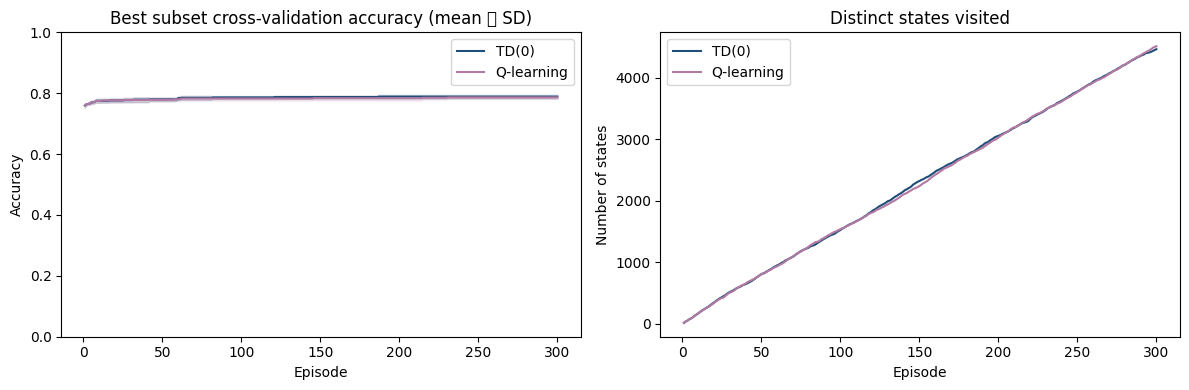

In [ ]:
# ---------- Learning curves: best subset accuracy score and state exploration ----------
ep = np.arange(1, cfg["N_EPISODES"] + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, ag_d, col in [
    ("TD(0)", agents, PAPER_COLORS["RL (TD0)"]),
    ("Q-learning", agents_q, PAPER_COLORS["RL (Q-learning)"])
]:
    B = np.array([ag_d[s].hist["best_score"] for s in cfg["SEEDS"]])
    S = np.array([ag_d[s].hist["n_states"] for s in cfg["SEEDS"]])
    ax[0].plot(ep, B.mean(0), color=col, label=name)
    ax[0].fill_between(ep, B.mean(0)-B.std(0), B.mean(0)+B.std(0), color=col, alpha=.15)
    ax[1].plot(ep, S.mean(0), color=col, label=name)
ax[0].set_title("Best subset cross-validation accuracy (mean  SD)")
ax[0].set_xlabel("Episode")
ax[0].set_ylabel("Accuracy")
ax[0].set_ylim(0, 1)
ax[0].legend()
ax[1].set_title("Distinct states visited")
ax[1].set_xlabel("Episode")
ax[1].set_ylabel("Number of states")
ax[1].legend()
plt.tight_layout()
plt.show()

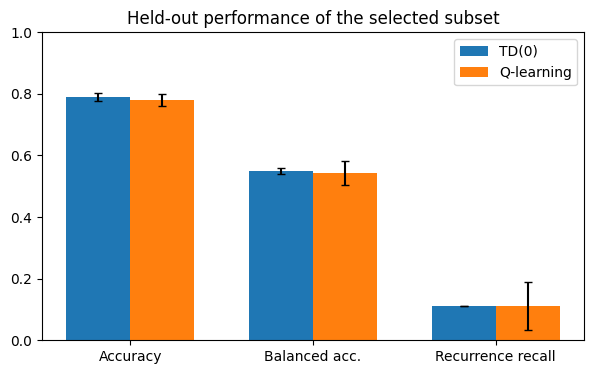

In [ ]:
# ---------- Held-out comparison bar chart ----------
labels = ["test_acc", "test_bal_acc", "test_recall_R"]
x = np.arange(len(labels)); w = 0.35
plt.figure(figsize=(7, 4))
plt.bar(x - w/2, [res_td0[l].mean() for l in labels], w, yerr=[res_td0[l].std() for l in labels], capsize=3, label="TD(0)")
plt.bar(x + w/2, [res_q[l].mean() for l in labels],   w, yerr=[res_q[l].std() for l in labels],   capsize=3, label="Q-learning")
plt.xticks(x, ["Accuracy", "Balanced acc.", "Recurrence recall"]); plt.ylim(0, 1); plt.legend()
plt.title("Held-out performance of the selected subset"); plt.show()

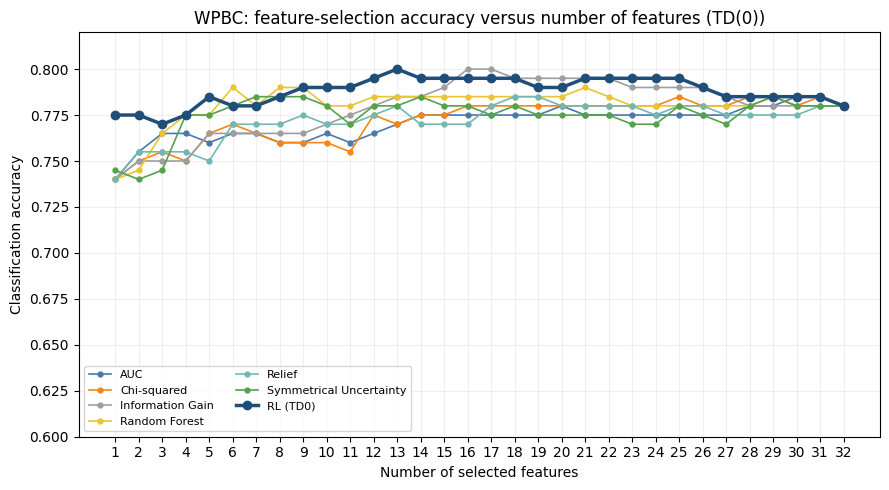

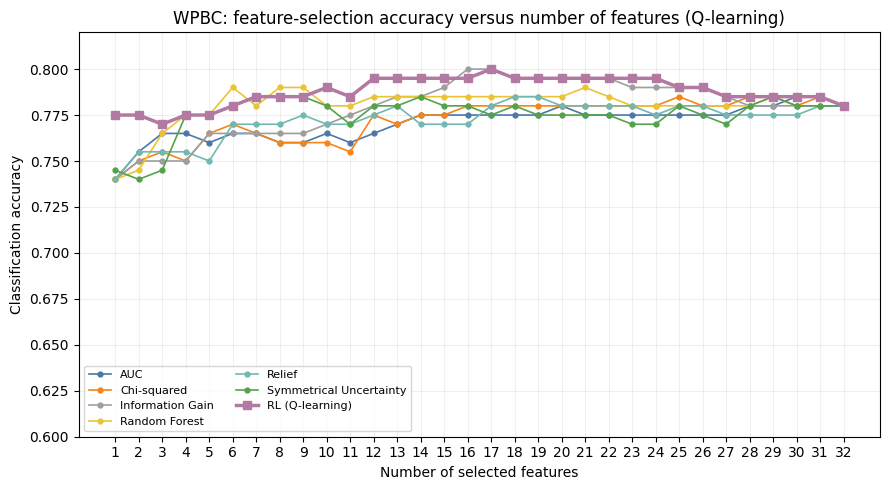

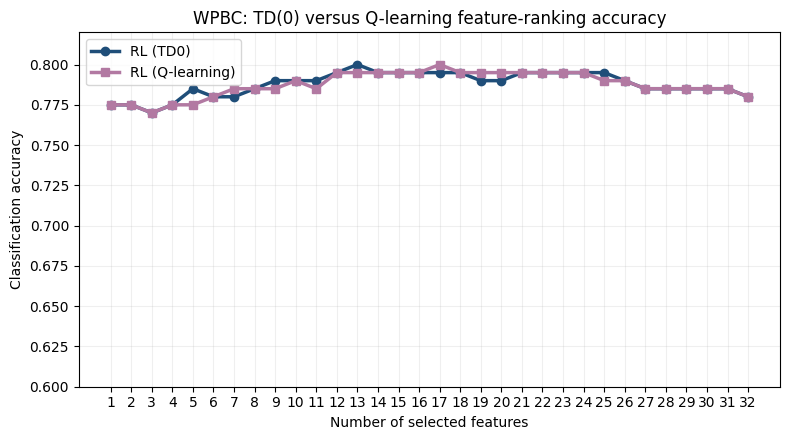

In [ ]:
# ---------- Three comparable WPBC accuracy plots: TD(0), Q-learning, and direct RL comparison ----------
curves_q = []
for seed in cfg["SEEDS"]:
    Xtr, Xte, ytr, yte = splits[seed]
    rk = np.array(agents_q[seed].ranking())
    curves_q.append([holdout_metrics(Xtr, ytr, Xte, yte, list(rk[:k]))["acc"] for k in range(1, N_FEAT + 1)])
curves_q = np.asarray(curves_q)

baseline_names = [n for n in curves.keys() if not n.startswith("RL")]
td_curve = np.mean(curves["RL (TD0)"], axis=0)
q_curve = curves_q.mean(axis=0)

def plot_paper_style_accuracy(title, rl_name, rl_values, include_filters=True, r_marker="o"):
    plt.figure(figsize=(9, 5))
    if include_filters:
        for name in baseline_names:
            plt.plot(range(1, N_FEAT + 1), np.mean(curves[name], axis=0),
                     color=PAPER_COLORS.get(name), lw=1.2, linestyle="-", marker="o", markersize=3.5, label=name)
    plt.plot(range(1, N_FEAT + 1), rl_values,
             color=PAPER_COLORS[rl_name], lw=2.5, linestyle="-", marker=r_marker, markersize=6,
             label=rl_name)
    plt.xlabel("Number of selected features")
    plt.ylabel("Classification accuracy")
    plt.title(title)
    plt.ylim(0.60, 0.82)
    plt.xticks(range(1, N_FEAT + 1))
    plt.grid(alpha=.2)
    plt.legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()

plot_paper_style_accuracy(
    "WPBC: feature-selection accuracy versus number of features (TD(0))",
    "RL (TD0)", td_curve, include_filters=True, r_marker="o")

plot_paper_style_accuracy(
    "WPBC: feature-selection accuracy versus number of features (Q-learning)",
    "RL (Q-learning)", q_curve, include_filters=True, r_marker="s")

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, N_FEAT + 1), td_curve, color=PAPER_COLORS["RL (TD0)"],
         lw=2.5, linestyle="-", marker="o", markersize=6, label="RL (TD0)")
plt.plot(range(1, N_FEAT + 1), q_curve, color=PAPER_COLORS["RL (Q-learning)"],
         lw=2.5, linestyle="-", marker="s", markersize=6, label="RL (Q-learning)")
plt.xlabel("Number of selected features")
plt.ylabel("Classification accuracy")
plt.title("WPBC: TD(0) versus Q-learning feature-ranking accuracy")
plt.ylim(0.60, 0.82)
plt.xticks(range(1, N_FEAT + 1))
plt.grid(alpha=.2)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Screenshot viewer display code removed to maintain a clean workspace.

In [ ]:
# ---------- Do the two agents agree on which features matter? ----------
td_rank = pd.Series(np.mean([agents[s].aor for s in cfg["SEEDS"]], 0), index=FEATURES)
q_rank  = pd.Series(np.mean([np.where(np.isfinite(agents_q[s].mean_q()), agents_q[s].mean_q(), np.nan) for s in cfg["SEEDS"]], 0), index=FEATURES)
sel_td = pd.Series([np.mean([(agents[s].best_subset()[0] >> i) & 1 for s in cfg["SEEDS"]]) for i in range(N_FEAT)], index=FEATURES)
sel_q  = pd.Series([np.mean([(agents_q[s].best_subset()[0] >> i) & 1 for s in cfg["SEEDS"]]) for i in range(N_FEAT)], index=FEATURES)
feat = pd.DataFrame({"TD0_AOR": td_rank, "Q_meanQ": q_rank, "TD0_selected_freq": sel_td, "Q_selected_freq": sel_q})
print("Spearman rank correlation (TD0 AOR vs Q mean-Q):", round(feat[["TD0_AOR", "Q_meanQ"]].corr(method="spearman").iloc[0, 1], 3))
print("Selection-frequency overlap (Jaccard of features chosen in >=50% seeds):",
      round(len(set(feat.index[feat.TD0_selected_freq >= .5]) & set(feat.index[feat.Q_selected_freq >= .5])) /
            max(1, len(set(feat.index[feat.TD0_selected_freq >= .5]) | set(feat.index[feat.Q_selected_freq >= .5]))), 3))
feat.sort_values("Q_meanQ", ascending=False).head(15).round(4)

Spearman rank correlation (TD0 AOR vs Q mean-Q): 0.93
Selection-frequency overlap (Jaccard of features chosen in >=50% seeds): 0.8


,TD0_AOR,Q_meanQ,TD0_selected_freq,Q_selected_freq
fractal_dimension1,0.0018,0.0002,0.4,0.4
texture1,0.0021,0.0002,0.6,0.4
tumor_size,0.0014,0.0002,0.8,1.0
compactness1,0.0008,0.0001,0.2,0.0
compactness3,0.0007,0.0001,0.2,0.4
fractal_dimension3,0.0005,0.0001,0.4,0.2
smoothness2,0.0005,0.0001,0.2,0.2
concavity1,0.0002,0.0000,0.4,0.2
concavity3,0.0001,0.0000,0.0,0.2
concave_points1,-0.0003,-0.0000,0.2,0.4


In [ ]:
# ---------- Save results (Colab may disconnect) ----------
res_td0.to_csv("td0_results.csv"); res_q.to_csv("qlearning_results.csv"); cmp.to_csv("td0_vs_q_comparison.csv")
try:
    from google.colab import files
    for f in ["td0_results.csv", "qlearning_results.csv", "td0_vs_q_comparison.csv"]: files.download(f)
except Exception as e:
    print("Saved in the Colab file panel (download skipped):", e)

In [ ]:
# Duplicate Q-learning run cell removed to maintain a clean workspace.

In [ ]:
# ---------- Side-by-side comparison ----------
metrics = ["search_cv_score", "test_acc", "test_bal_acc", "test_recall_R", "n_selected", "states_visited", "svm_evals", "secs"]
cmp = pd.concat({"TD0": res_td0[metrics], "Q-learning": res_q[metrics]}, axis=1)
display(cmp.round(3))

summ = pd.DataFrame({
    m: {
        "TD0 mean": res_td0[m].mean(), "TD0 std": res_td0[m].std(),
        "Q mean": res_q[m].mean(), "Q std": res_q[m].std(),
        "Q - TD0": res_q[m].mean() - res_td0[m].mean()
    } for m in metrics
}).T
display(summ.round(4))

TD0                                                 \
     search_cv_score test_acc test_bal_acc test_recall_R n_selected   
seed                                                                  
20             0.791    0.775        0.539         0.111          6   
40             0.785    0.800        0.556         0.111          7   
60             0.791    0.775        0.539         0.111          7   
80             0.798    0.800        0.556         0.111          4   
100            0.779    0.800        0.556         0.111         11   

                                            Q-learning                        \
     states_visited svm_evals     secs search_cv_score test_acc test_bal_acc   
seed                                                                           
20             4277      4278  200.897           0.791    0.775        0.539   
40             4181      4182  167.925           0.785    0.800        0.556   
60             4792      4793  189.528           0.792    0.800        0.595   
80             4547      4548  184.988           0.785    0.750        0.484   
100            4547      4548  179.788           0.779    0.775        0.539   

                                                                 
     test_recall_R n_selected states_visited svm_evals     secs  
seed                                                             
20           0.111          6           4545      4546  197.311  
40           0.111          7           4614      4615  184.247  
60           0.222         14           4493      4494  189.856  
80           0.000         11           4386      4387  182.255  
100          0.111          2           4548      4549  187.560

,TD0 mean,TD0 std,Q mean,Q std,Q - TD0
search_cv_score,0.7888,0.0071,0.7863,0.0053,-0.0025
test_acc,0.7900,0.0137,0.7800,0.0209,-0.0100
test_bal_acc,0.5491,0.0088,0.5427,0.0399,-0.0065
test_recall_R,0.1111,0.0000,0.1111,0.0786,0.0000
n_selected,7.0000,2.5495,8.0000,4.6368,1.0000
states_visited,4468.8000,243.0560,4517.2000,84.9865,48.4000
svm_evals,4469.8000,243.0560,4518.2000,84.9865,48.4000
secs,184.6251,12.1578,188.2456,5.8549,3.6205


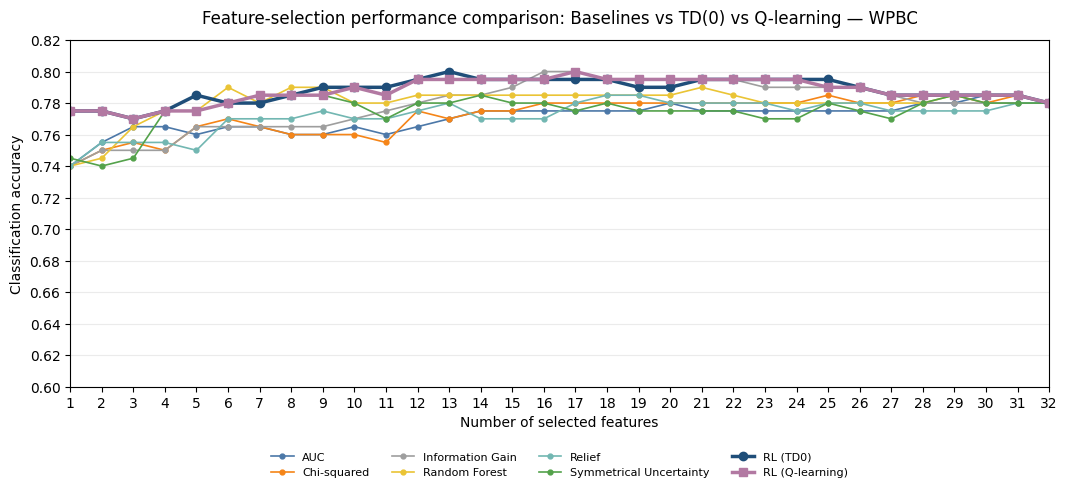

In [ ]:
# ---------- Plot Q-learning vs TD(0) comparative curves in the target style ----------
curves_q = []
for seed in cfg["SEEDS"]:
    Xtr, Xte, ytr, yte = splits[seed]
    rk = np.array(agents_q[seed].ranking())
    curves_q.append([holdout_metrics(Xtr, ytr, Xte, yte, list(rk[:k]))["acc"] for k in range(1, N_FEAT + 1)])
curves_q = np.asarray(curves_q)

td_curve = np.mean(curves["RL (TD0)"], axis=0)
q_curve = curves_q.mean(axis=0)

feature_counts = np.arange(1, N_FEAT + 1)
fig, ax = plt.subplots(figsize=(11, 5.5))

# Baseline curves (solid thin lines, distinct markers)
baseline_names = [n for n in curves.keys() if not n.startswith("RL")]
for name in baseline_names:
    ax.plot(
        feature_counts,
        np.mean(curves[name], axis=0),
        color=PAPER_COLORS.get(name, "#333333"),
        linewidth=1.2,
        linestyle="-",
        marker="o",
        markersize=3.5,
        label=name
    )

# Highlighted RL curves (thick solid lines with clear prominent markers / 'rich dots')
ax.plot(
    feature_counts,
    td_curve,
    color=PAPER_COLORS["RL (TD0)"],
    linewidth=2.5,
    linestyle="-",
    marker="o",
    markersize=6,
    label="RL (TD0)"
)

ax.plot(
    feature_counts,
    q_curve,
    color=PAPER_COLORS["RL (Q-learning)"],
    linewidth=2.5,
    linestyle="-",
    marker="s",
    markersize=6,
    label="RL (Q-learning)"
)

ax.set_title("Feature-selection performance comparison: Baselines vs TD(0) vs Q-learning — WPBC", fontsize=12, pad=12)
ax.set_xlabel("Number of selected features")
ax.set_ylabel("Classification accuracy")
ax.set_ylim(0.60, 0.82)
ax.set_yticks(np.arange(0.60, 0.821, 0.02))
ax.set_xlim(1, N_FEAT)
ax.set_xticks(feature_counts)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
fig.subplots_adjust(left=0.09, right=0.98, top=0.88, bottom=0.25)
plt.show()

### How to interpret (write this in your report – only after seeing your numbers)
* **Primary question:** does Q-learning find subsets with higher *held-out* accuracy / balanced accuracy than TD(0)? Look at the paired differences, win counts and the seed-to-seed spread – with ~40 test patients, differences of 1-3 points are within noise.
* **Efficiency:** compare `svm_evals`, `states_visited` and the learning curve (does one reach a good CV score in fewer episodes?).
* **Mechanism:** Q-learning's greedy choice is state-dependent, TD(0)'s is global (AOR). If rankings correlate highly, the agents are effectively learning the same feature importance.
* **Caveats to state:** search-CV score is optimistic (winner's curse); small test set; hyper-parameters (alpha, gamma, epsilon, episodes) were not tuned for either agent; tabular Q over 2^32 states is sparse – most states are visited once, so Q(s,.) is rarely reused (this is the paper's own motivation for function approximation).